11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Epoch 1, Loss: 157.7112
Epoch 2, Loss: 151.3618
Epoch 3, Loss: 141.9552
Epoch 4, Loss: 149.2396
Epoch 5, Loss: 164.2610
Epoch 6, Loss: 152.3530
Epoch 7, Loss: 159.8027
Epoch 8, Loss: 155.1526
Epoch 9, Loss: 142.9435
Epoch 10, Loss: 146.1578


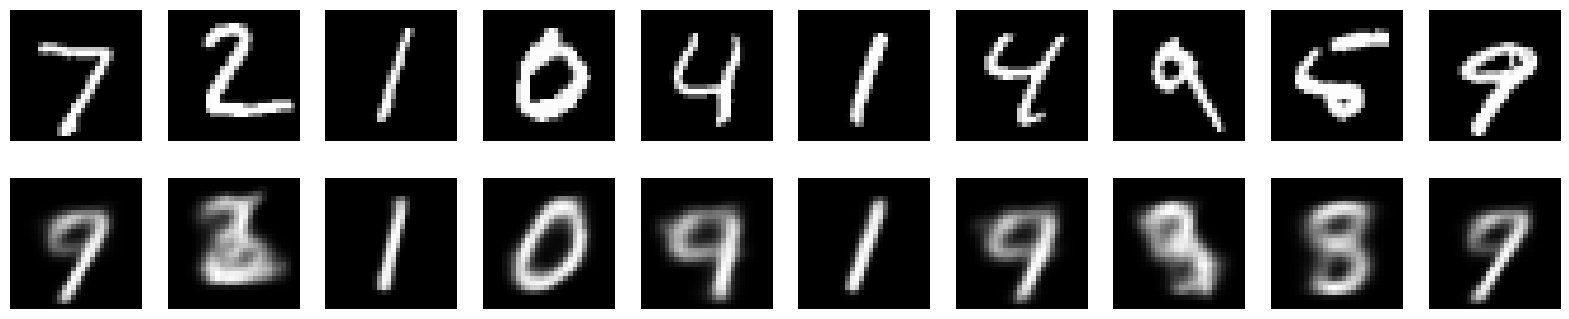

In [1]:
import tensorflow as tf
from tensorflow.keras import layers, Model
import numpy as np
import matplotlib.pyplot as plt

# Loading MNIST dataset
def load_data():
    (x_train, _), (x_test, _) = tf.keras.datasets.mnist.load_data()
    x_train = x_train.astype('float32') / 255.0
    x_test = x_test.astype('float32') / 255.0
    x_train = np.expand_dims(x_train, -1)  # Add channel dimension
    x_test = np.expand_dims(x_test, -1)
    return x_train, x_test

# Defining Encoder
class Encoder(Model):
    def __init__(self, latent_dim):
        super(Encoder, self).__init__()
        self.conv1 = layers.Conv2D(32, (3, 3), activation='relu', strides=2, padding='same')
        self.conv2 = layers.Conv2D(64, (3, 3), activation='relu', strides=2, padding='same')
        self.flatten = layers.Flatten()
        self.dense_mean = layers.Dense(latent_dim)
        self.dense_log_var = layers.Dense(latent_dim)

    def call(self, x):
        x = self.conv1(x)
        x = self.conv2(x)
        x = self.flatten(x)
        mean = self.dense_mean(x)
        log_var = self.dense_log_var(x)
        return mean, log_var

# Defining Decoder
class Decoder(Model):
    def __init__(self):
        super(Decoder, self).__init__()
        self.dense = layers.Dense(7 * 7 * 64, activation='relu')
        self.reshape = layers.Reshape((7, 7, 64))
        self.deconv1 = layers.Conv2DTranspose(64, (3, 3), activation='relu', strides=2, padding='same')
        self.deconv2 = layers.Conv2DTranspose(32, (3, 3), activation='relu', strides=2, padding='same')
        self.output_layer = layers.Conv2DTranspose(1, (3, 3), activation='sigmoid', padding='same')

    def call(self, x):
        x = self.dense(x)
        x = self.reshape(x)
        x = self.deconv1(x)
        x = self.deconv2(x)
        return self.output_layer(x)

# Defining VAE Model
class VAE(Model):
    def __init__(self, encoder, decoder):
        super(VAE, self).__init__()
        self.encoder = encoder
        self.decoder = decoder

    def call(self, x):
        mean, log_var = self.encoder(x)
        z = self.sampling(mean, log_var)
        reconstructed = self.decoder(z)
        return reconstructed

    def sampling(self, mean, log_var):
        epsilon = tf.random.normal(shape=tf.shape(mean))
        return mean + tf.exp(0.5 * log_var) * epsilon

# Loss Function
def compute_loss(model, x):
    mean, log_var = model.encoder(x)
    z = model.sampling(mean, log_var)
    reconstruction = model.decoder(z)
    reconstruction_loss = tf.reduce_mean(tf.reduce_sum(tf.keras.losses.binary_crossentropy(x, reconstruction), axis=(1, 2)))
    kl_divergence = -0.5 * tf.reduce_mean(tf.reduce_sum(1 + log_var - tf.square(mean) - tf.exp(log_var), axis=1))
    return reconstruction_loss + kl_divergence

# Training the Model
def train(vae, x_train, epochs=10, batch_size=64):
    optimizer = tf.keras.optimizers.Adam()
    dataset = tf.data.Dataset.from_tensor_slices(x_train).shuffle(buffer_size=1024).batch(batch_size)

    for epoch in range(epochs):
        for step, x_batch in enumerate(dataset):
            with tf.GradientTape() as tape:
                loss = compute_loss(vae, x_batch)
            gradients = tape.gradient(loss, vae.trainable_variables)
            optimizer.apply_gradients(zip(gradients, vae.trainable_variables))

        print(f"Epoch {epoch + 1}, Loss: {loss.numpy():.4f}")

# Visualization of Results
def visualize_results(vae, x_test, num_images=10):
    mean, log_var = vae.encoder(x_test)
    z = vae.sampling(mean, log_var)
    reconstructed = vae.decoder(z)

    fig, axes = plt.subplots(2, num_images, figsize=(20, 4))
    for i in range(num_images):
        axes[0, i].imshow(x_test[i].squeeze(), cmap='gray')
        axes[0, i].axis('off')
        axes[1, i].imshow(reconstructed[i].numpy().squeeze(), cmap='gray')
        axes[1, i].axis('off')
    plt.show()

# Main Function
if __name__ == "__main__":
    latent_dim = 2
    x_train, x_test = load_data()

    encoder = Encoder(latent_dim)
    decoder = Decoder()
    vae = VAE(encoder, decoder)

    train(vae, x_train, epochs=10, batch_size=64)
    visualize_results(vae, x_test)
